# Assignment 1: Five-model comparison on Fashion-MNIST

This notebook trains and evaluates the five mandatory models under one shared split: Linear, MLP, CNN, GRU and Transformer.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "assignment1").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "assignment1" / "src"))
sys.path.insert(0, str(REPO_ROOT))

import copy
import json
import time

import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

from training_loop import preprocess, set_seed
from utils.dataloader import get_dataloaders, load_split
from utils.experiment_utils import (
    measure_inference_time,
    plot_confusion,
    plot_curves,
    plot_examples,
)
from models.linear import LinearClassifier
from models.mlp import MLP
from models.cnn import CNNClassifier
from models.rnn import GRUClassifier
from models.transformer import TransformerClassifier


In [2]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

SEED = 42
EPOCHS = 10
LR = 1e-3
BATCH_SIZE = 64
MONITOR = "validation_macro_f1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CHECKPOINT_DIR = REPO_ROOT / "assignment1" / "checkpoints"
RESULTS_DIR = REPO_ROOT / "assignment1" / "results"
for path in [
    CHECKPOINT_DIR,
    RESULTS_DIR,
    RESULTS_DIR / "curves",
    RESULTS_DIR / "confusion",
    RESULTS_DIR / "examples",
    RESULTS_DIR / "history",
]:
    path.mkdir(parents=True, exist_ok=True)


Device: cuda


## 1. Dataset, split and DataLoaders

In [3]:
set_seed()

(X_train, y_train), (X_validate, y_validate), (X_test, y_test) = load_split(dataset_name="fashion_mnist")
(X_train, X_validate, X_test), (mean, std) = preprocess(X_train, X_validate, X_test)
train_loader, validation_loader, test_loader = get_dataloaders(
    X_train, y_train, X_validate, y_validate, X_test, y_test,
    batch_size=BATCH_SIZE,
)

print("Train/Validation/Test:", len(y_train), len(y_validate), len(y_test))
print("Input shape and dtype:", tuple(X_train.shape), X_train.dtype)


Train/Validation/Test: 48000 12000 10000
Input shape and dtype: (48000, 1, 28, 28) torch.float32


## 2. Training and evaluation

In [4]:
@torch.no_grad()
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions, targets = [], []

    for X, y in dataloader:
        X = X.to(device)
        y = y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * X.size(0)
        predictions.append(logits.argmax(dim=1).cpu())
        targets.append(y.cpu())

    predictions = torch.cat(predictions).numpy()
    targets = torch.cat(targets).numpy()
    loss = total_loss / len(targets)
    accuracy = float((predictions == targets).mean())
    macro_f1 = float(f1_score(targets, predictions, average="macro"))
    return loss, accuracy, macro_f1, predictions, targets


In [5]:
def fit(model, train_loader, validation_loader, checkpoint_path, device,
        epochs, lr, seed, monitor, clip_grad_norm=1.0):
    set_seed(seed)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
        "validation_macro_f1": [],
        "epoch_time": [],
    }
    best_value = float("inf") if monitor == "validation_loss" else -float("inf")
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for X, y in train_loader:
            X = X.to(device)
            y = y.to(device)
            logits = model(X)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            if clip_grad_norm is not None and clip_grad_norm > 0:
                nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
            optimizer.step()

            total_loss += loss.item() * X.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += y.size(0)

        train_loss = total_loss / total
        train_accuracy = correct / total
        validation_loss, validation_accuracy, validation_macro_f1, _, _ = evaluate_model(
            model, validation_loader, criterion, device
        )
        epoch_time = time.perf_counter() - start

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)
        history["validation_macro_f1"].append(validation_macro_f1)
        history["epoch_time"].append(epoch_time)

        current = {
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "validation_macro_f1": validation_macro_f1,
        }[monitor]
        improved = current < best_value if monitor == "validation_loss" else current > best_value

        if improved:
            best_value = current
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            checkpoint_path = Path(checkpoint_path)
            checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save(
                {
                    "model_state_dict": best_state,
                    "epoch": best_epoch,
                    "monitor": monitor,
                    "value": best_value,
                },
                checkpoint_path,
            )

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"Train loss: {train_loss:.4f} Train accuracy: {train_accuracy:.4f} "
            f"Validation loss: {validation_loss:.4f} "
            f"Validation accuracy: {validation_accuracy:.4f} "
            f"Validation macro-F1: {validation_macro_f1:.4f} "
            f"Time: {epoch_time:.1f}s"
        )

    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    history["best_value"] = best_value
    history["monitor"] = monitor
    return history


## 3. Train all five models

In [6]:
model_builders = {
    "Linear": lambda: LinearClassifier(input_shape=(1, 28, 28)),
    "MLP": lambda: MLP(input_dim=784),
    "CNN": lambda: CNNClassifier(input_shape=(1, 28, 28)),
    "GRU": lambda: GRUClassifier(input_shape=(1, 28, 28)),
    "Transformer": lambda: TransformerClassifier(input_shape=(1, 28, 28)),
}


In [7]:
criterion = nn.CrossEntropyLoss()
rows = []
histories = {}
per_class = {}
confusion_matrices = {}

for display_name, build in model_builders.items():
    print(f"\n{'=' * 70}\nTraining {display_name}\n{'=' * 70}")

    set_seed(SEED)
    model = build().to(device)
    params = model.num_para()
    checkpoint_path = CHECKPOINT_DIR / f"{display_name.lower()}.pt"

    start = time.perf_counter()
    history = fit(
        model,
        train_loader,
        validation_loader,
        checkpoint_path,
        device,
        EPOCHS,
        LR,
        SEED,
        MONITOR,
        clip_grad_norm=1.0,
    )
    train_time = time.perf_counter() - start

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])

    test_loss, test_accuracy, test_macro_f1, predictions, targets = evaluate_model(
        model, test_loader, criterion, device
    )
    inference_time, inference_ms = measure_inference_time(model, test_loader, device)

    precision, recall, f1, support = precision_recall_fscore_support(
        targets, predictions, labels=list(range(10)), average=None, zero_division=0
    )
    cm = confusion_matrix(targets, predictions, labels=list(range(10)))

    histories[display_name] = history
    per_class[display_name] = [
        {
            "class_id": index,
            "class_name": CLASS_NAMES[index],
            "precision": float(precision[index]),
            "recall": float(recall[index]),
            "f1": float(f1[index]),
            "support": int(support[index]),
        }
        for index in range(10)
    ]
    confusion_matrices[display_name] = cm.tolist()

    with open(RESULTS_DIR / "history" / f"{display_name.lower()}.json", "w") as handle:
        json.dump(history, handle, indent=2)
    plot_curves(history, RESULTS_DIR / "curves" / f"{display_name.lower()}.png", display_name)
    plot_confusion(
        cm,
        CLASS_NAMES,
        RESULTS_DIR / "confusion" / f"{display_name.lower()}.png",
        f"{display_name} confusion matrix (test)",
    )
    plot_examples(
        X_test,
        targets,
        predictions,
        CLASS_NAMES,
        RESULTS_DIR / "examples" / f"{display_name.lower()}.png",
        f"{display_name} predictions",
        float(mean),
        float(std),
    )

    best_index = max(0, history["best_epoch"] - 1)
    rows.append({
        "Model": display_name,
        "Params": int(params),
        "Best epoch": int(history["best_epoch"]),
        "Val loss": float(history["validation_loss"][best_index]),
        "Val accuracy": float(history["validation_accuracy"][best_index]),
        "Val macro-F1": float(history["validation_macro_f1"][best_index]),
        "Test loss": float(test_loss),
        "Test accuracy": float(test_accuracy),
        "Test macro-F1": float(test_macro_f1),
        "Train time (s)": float(train_time),
        "Inference time (s)": float(inference_time),
        "Inference (ms/sample)": float(inference_ms),
    })

    print(
        f"{display_name}: params={params:,} best_epoch={history['best_epoch']} "
        f"test_acc={test_accuracy:.4f} test_macro_f1={test_macro_f1:.4f} "
        f"train_time={train_time:.1f}s inference={inference_ms:.3f}ms/sample"
    )



Training Linear
Epoch 1/10 Train loss: 0.5420 Train accuracy: 0.8114 Validation loss: 0.4436 Validation accuracy: 0.8458 Validation macro-F1: 0.8429 Time: 1.5s
Epoch 2/10 Train loss: 0.4490 Train accuracy: 0.8444 Validation loss: 0.4285 Validation accuracy: 0.8501 Validation macro-F1: 0.8495 Time: 0.9s
Epoch 3/10 Train loss: 0.4336 Train accuracy: 0.8499 Validation loss: 0.4302 Validation accuracy: 0.8524 Validation macro-F1: 0.8484 Time: 0.9s
Epoch 4/10 Train loss: 0.4230 Train accuracy: 0.8517 Validation loss: 0.4224 Validation accuracy: 0.8510 Validation macro-F1: 0.8530 Time: 1.0s
Epoch 5/10 Train loss: 0.4158 Train accuracy: 0.8551 Validation loss: 0.4235 Validation accuracy: 0.8536 Validation macro-F1: 0.8498 Time: 0.9s
Epoch 6/10 Train loss: 0.4113 Train accuracy: 0.8549 Validation loss: 0.4467 Validation accuracy: 0.8433 Validation macro-F1: 0.8456 Time: 0.9s
Epoch 7/10 Train loss: 0.4079 Train accuracy: 0.8571 Validation loss: 0.4198 Validation accuracy: 0.8538 Validation mac

## 4. Results

In [8]:
results_df = pd.DataFrame(rows)
results_df.to_csv(RESULTS_DIR / "results.csv", index=False)

config = {
    "dataset": "fashion_mnist",
    "train_size": int(len(y_train)),
    "validation_size": int(len(y_validate)),
    "test_size": int(len(y_test)),
    "input_shape": [1, 28, 28],
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "monitor": MONITOR,
    "clip_grad_norm": 1.0,
    "augmentation": "none",
    "device": str(device),
    "torch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "normalization_mean": float(mean),
    "normalization_std": float(std),
}
with open(RESULTS_DIR / "results.json", "w") as handle:
    json.dump(
        {
            "config": config,
            "results": rows,
            "per_class": per_class,
            "confusion_matrix": confusion_matrices,
        },
        handle,
        indent=2,
    )
with open(RESULTS_DIR / "config.json", "w") as handle:
    json.dump(config, handle, indent=2)

results_df


,Model,Params,Best epoch,Val loss,Val accuracy,Val macro-F1,Test loss,Test accuracy,Test macro-F1,Train time (s),Inference time (s),Inference (ms/sample)
0,Linear,7850,8,0.407074,0.858917,0.859374,0.450646,0.8410,0.841540,9.570070,0.051295,0.005129
1,MLP,235146,8,0.306286,0.895500,0.895690,0.350751,0.8789,0.878940,12.811089,0.061577,0.006158
2,CNN,455946,7,0.220146,0.927583,0.927701,0.253198,0.9179,0.917860,20.530534,0.102730,0.010273
3,GRU,61962,8,0.270584,0.901333,0.900859,0.291979,0.8893,0.888519,52.532056,0.251761,0.025176
4,Transformer,69450,8,0.295223,0.896000,0.895942,0.316064,0.8871,0.886915,32.469089,0.121207,0.012121


## 5. Curves, confusion matrices, and prediction examples

### Linear


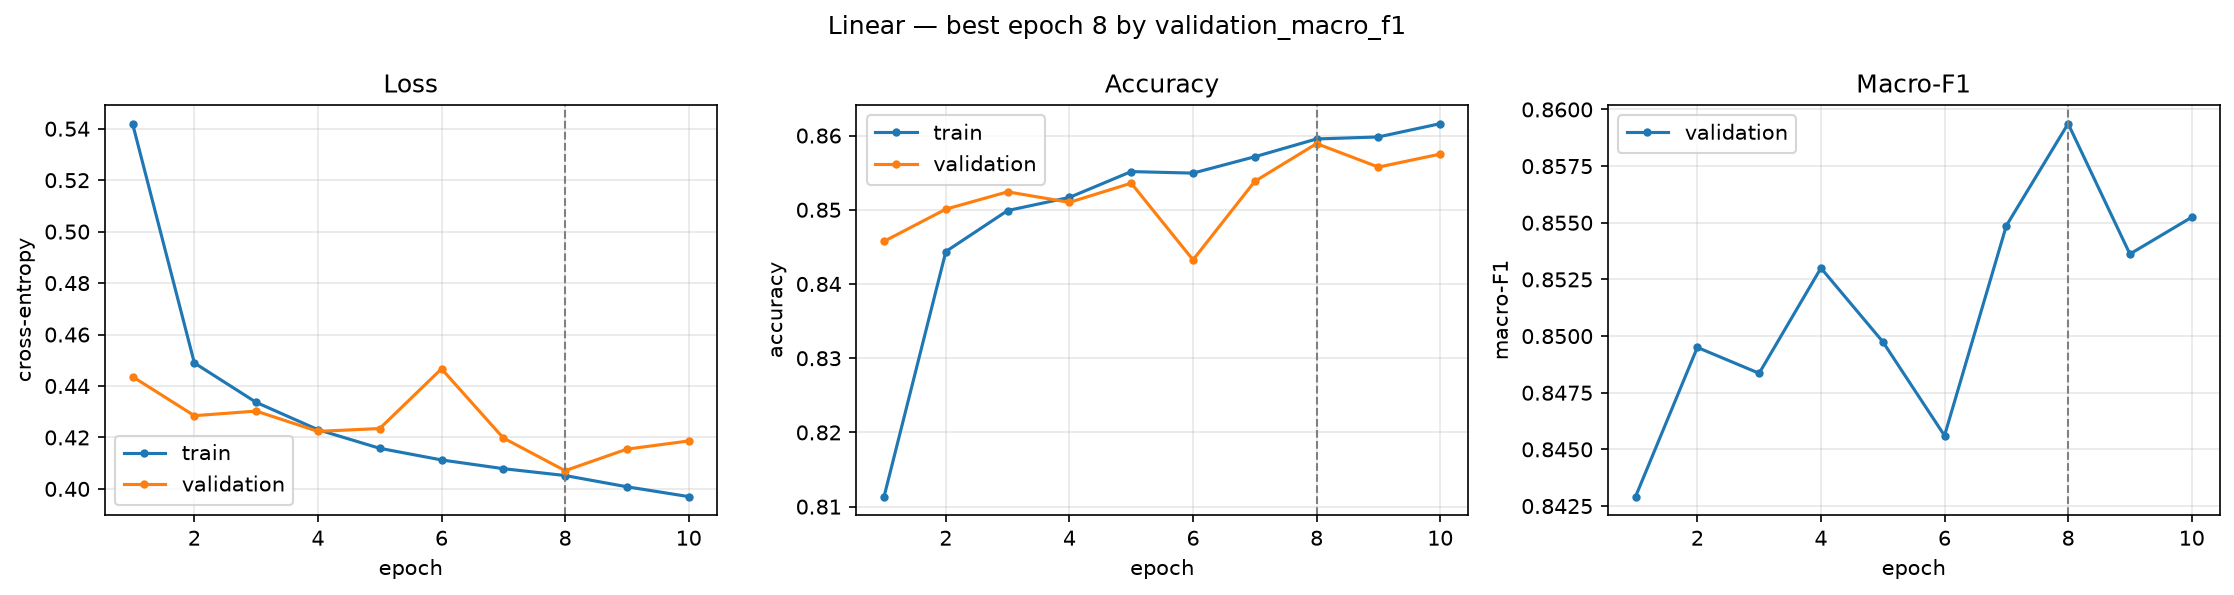

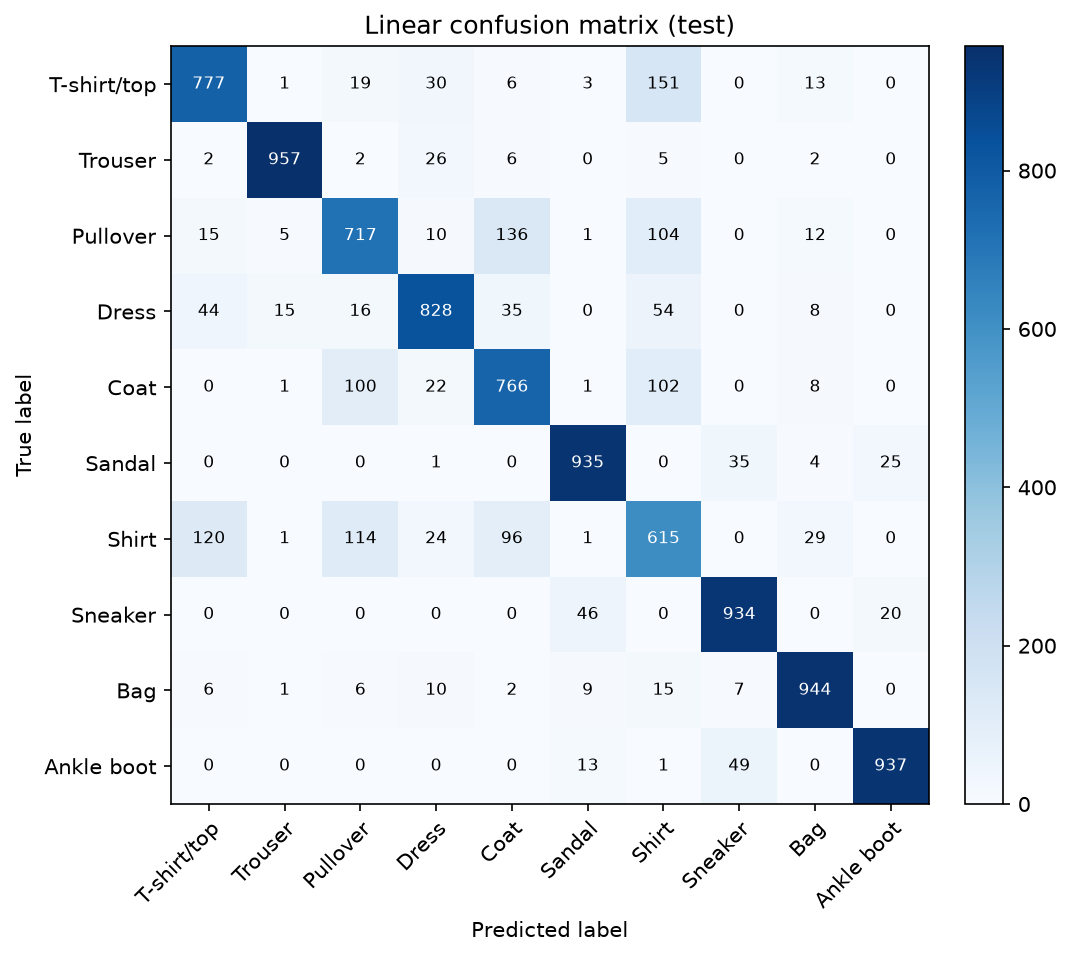

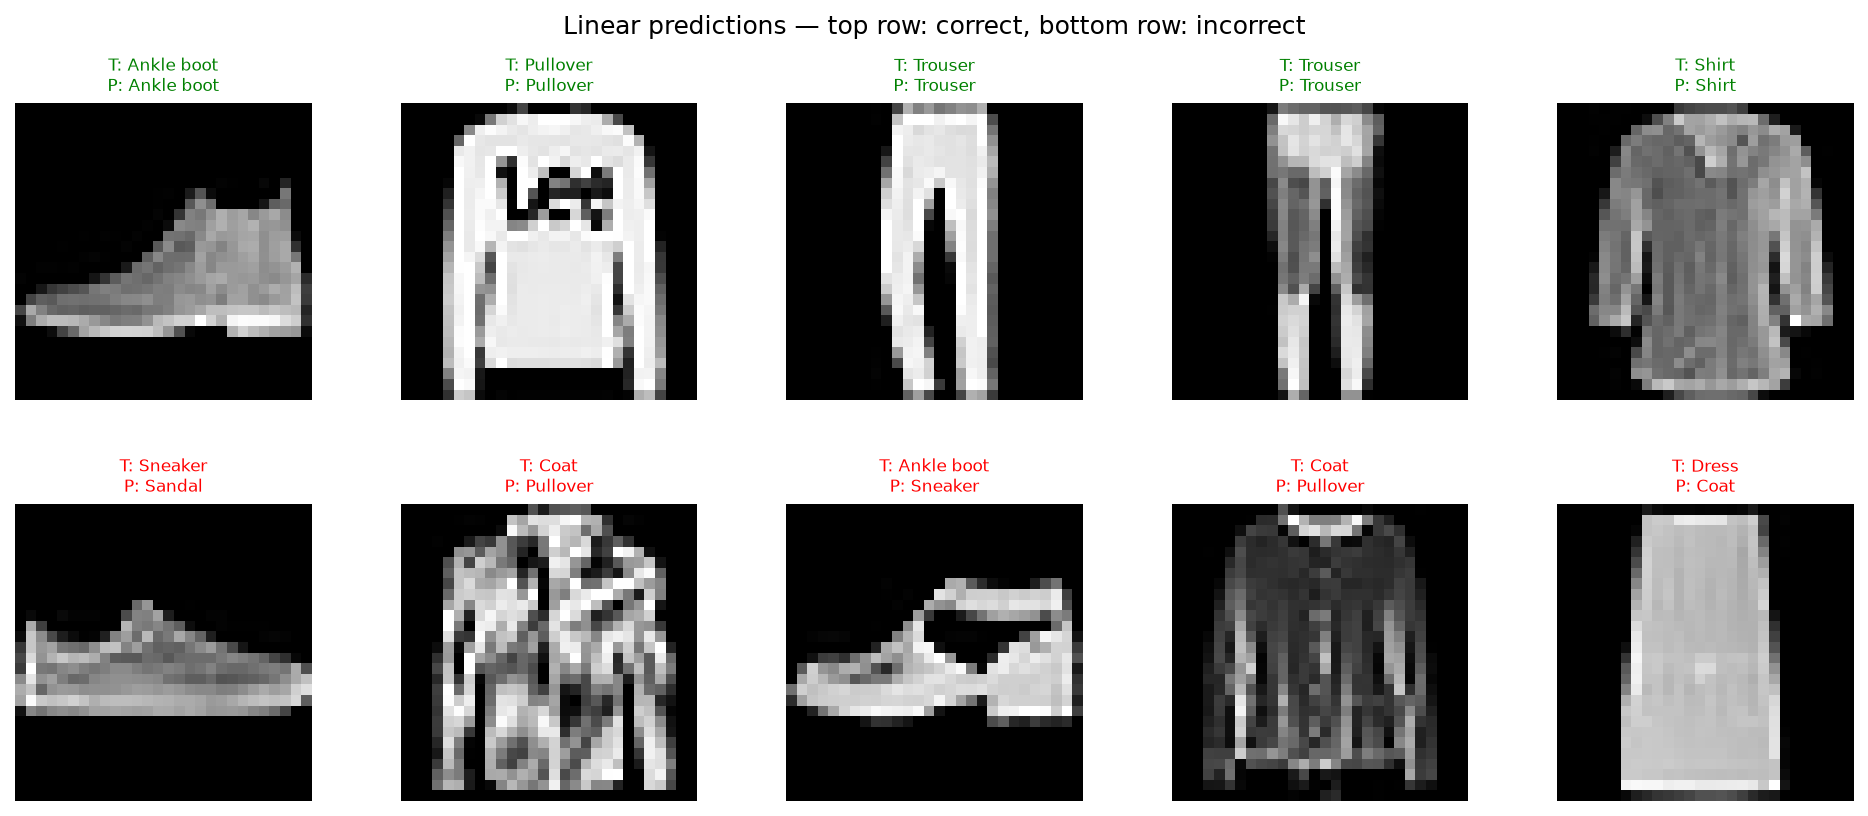

### MLP


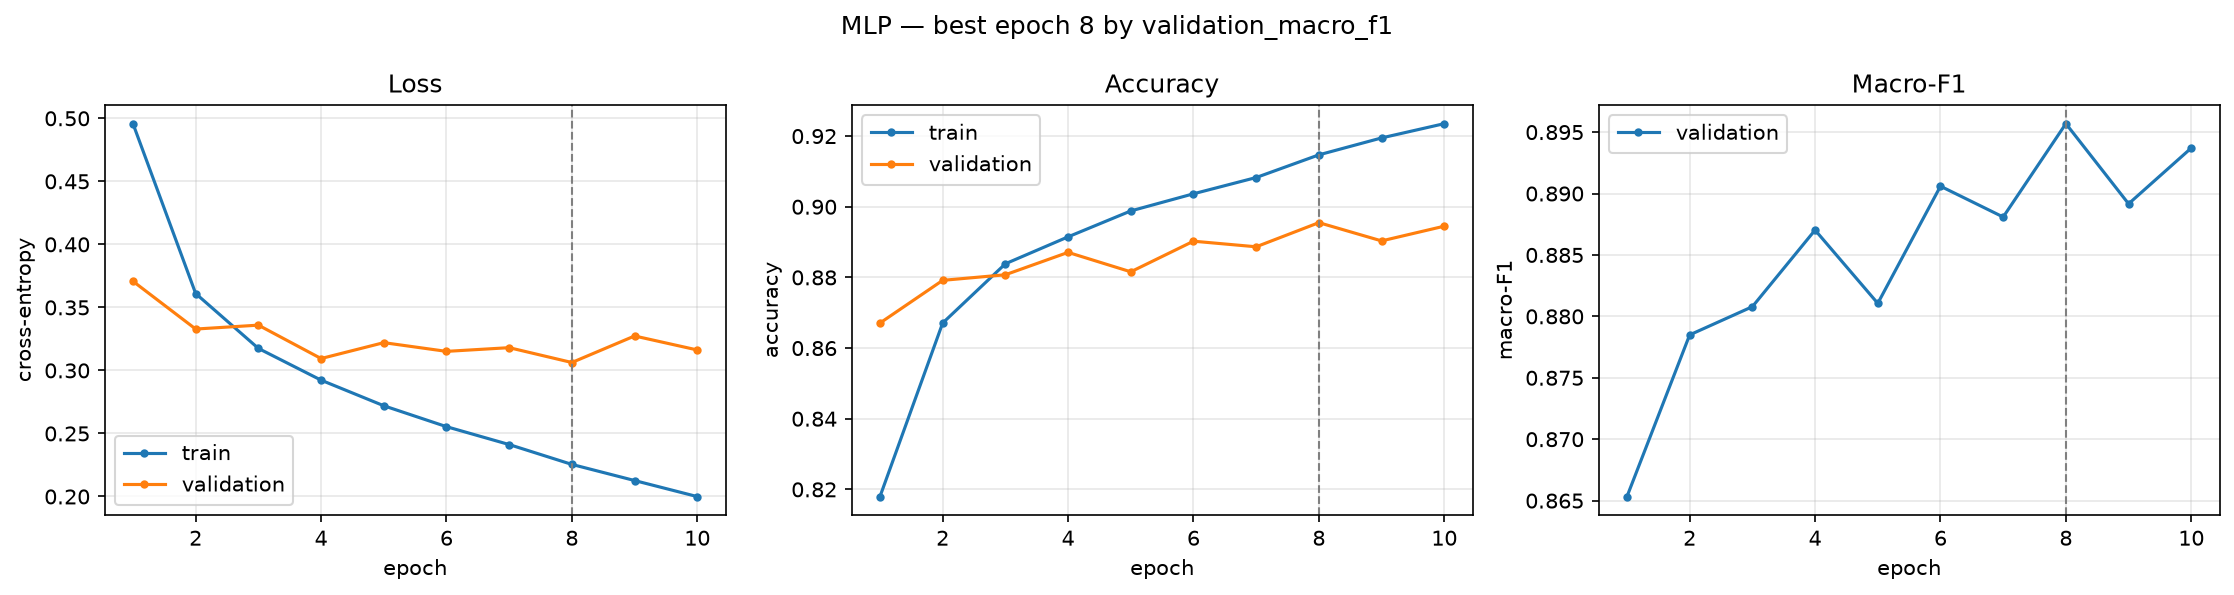

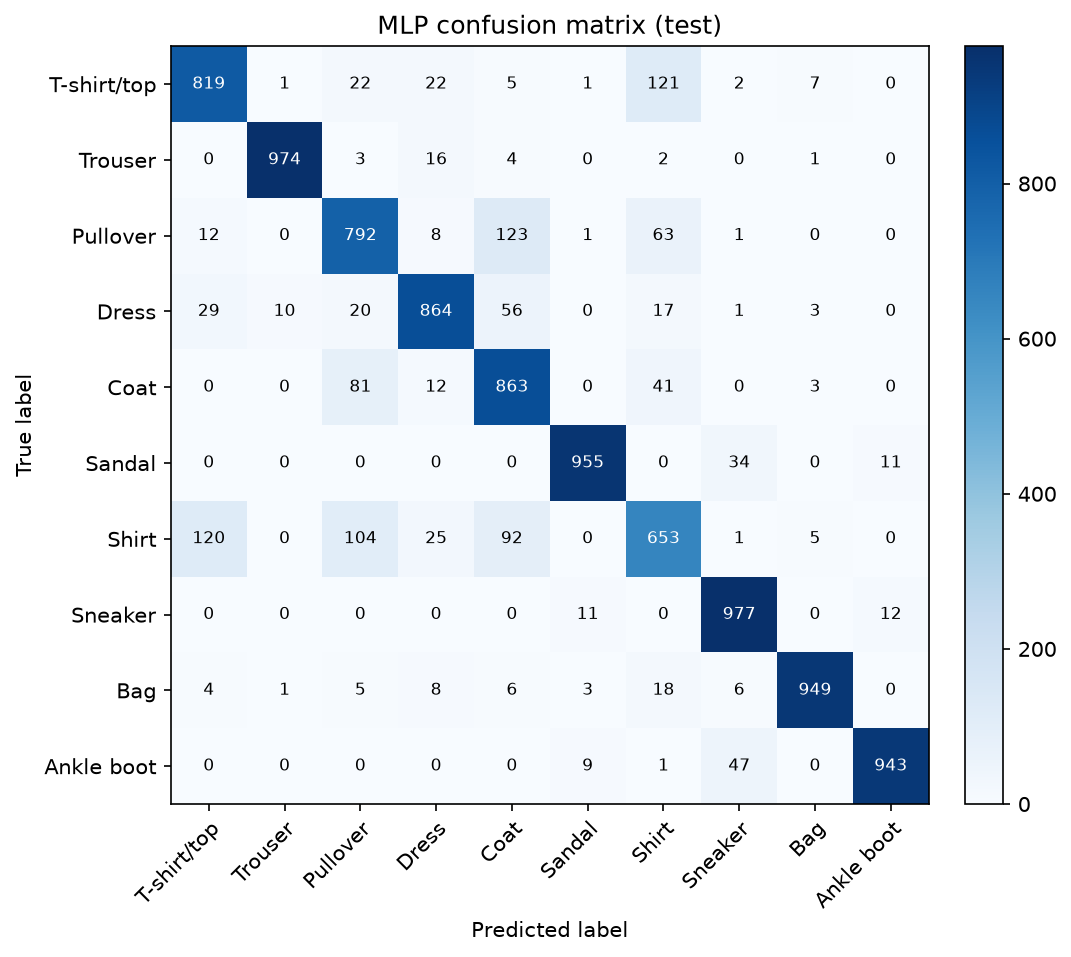

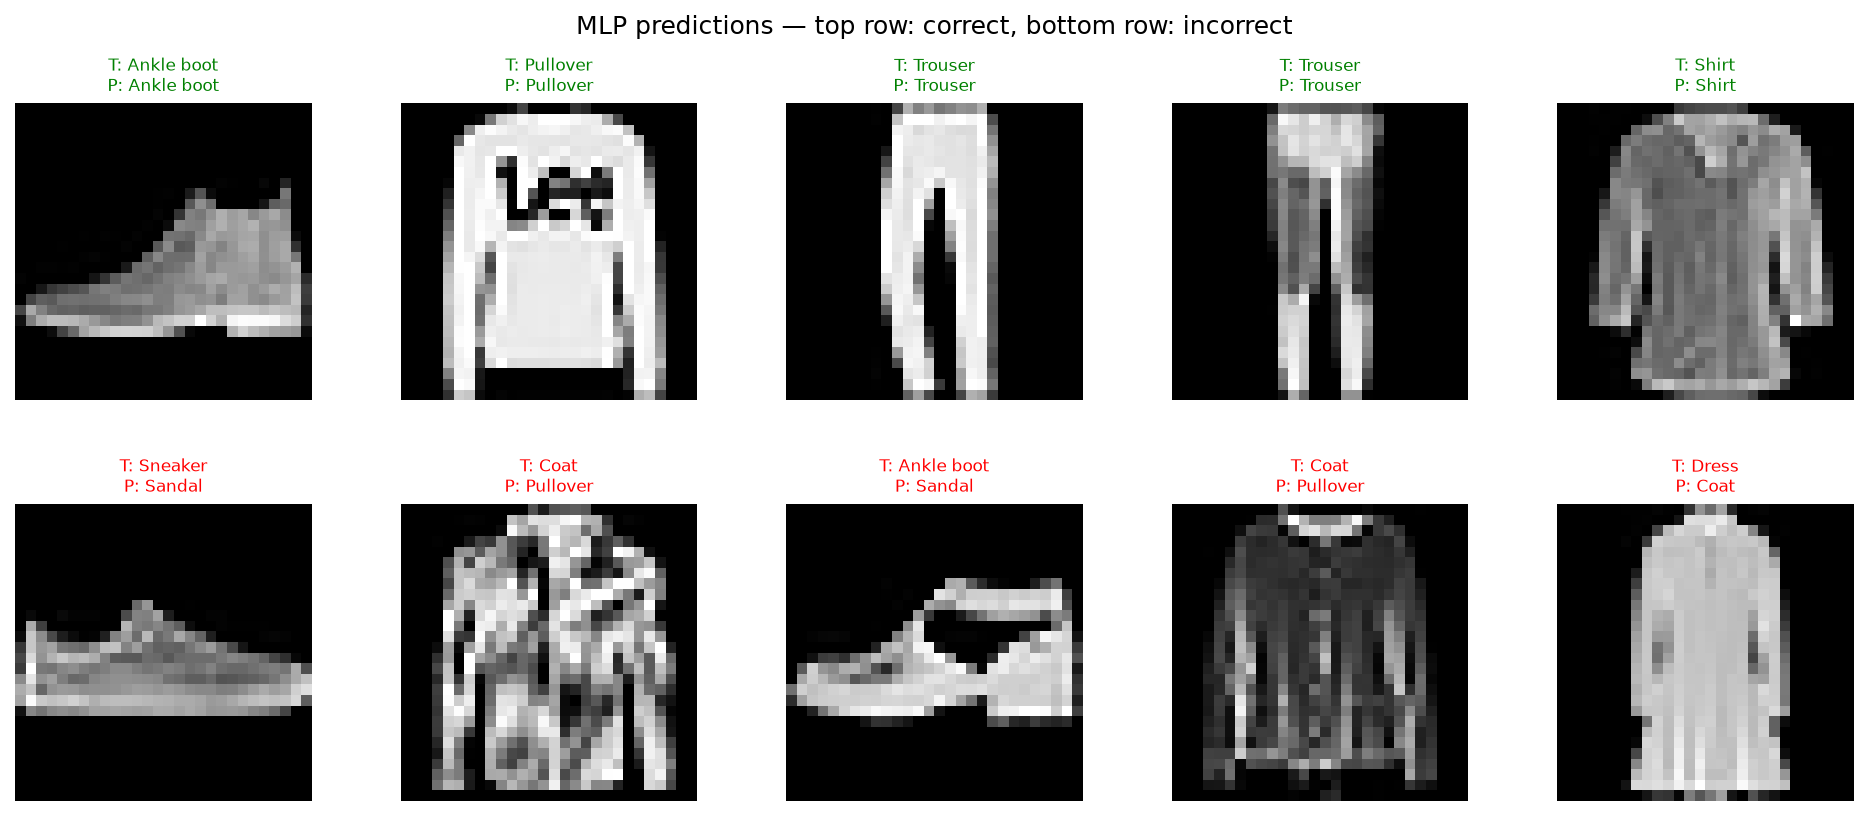

### CNN


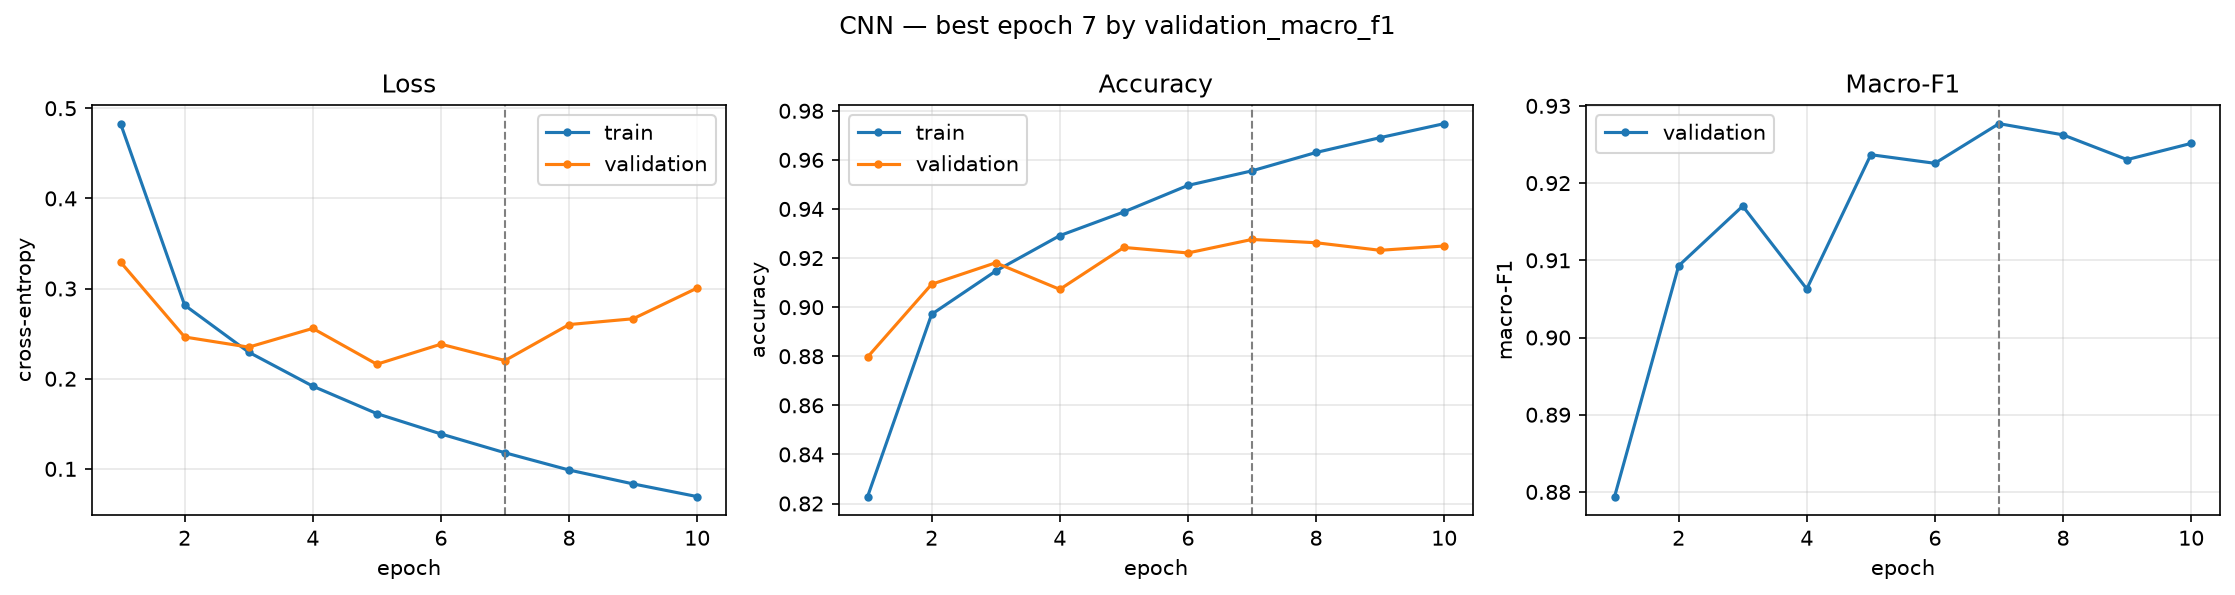

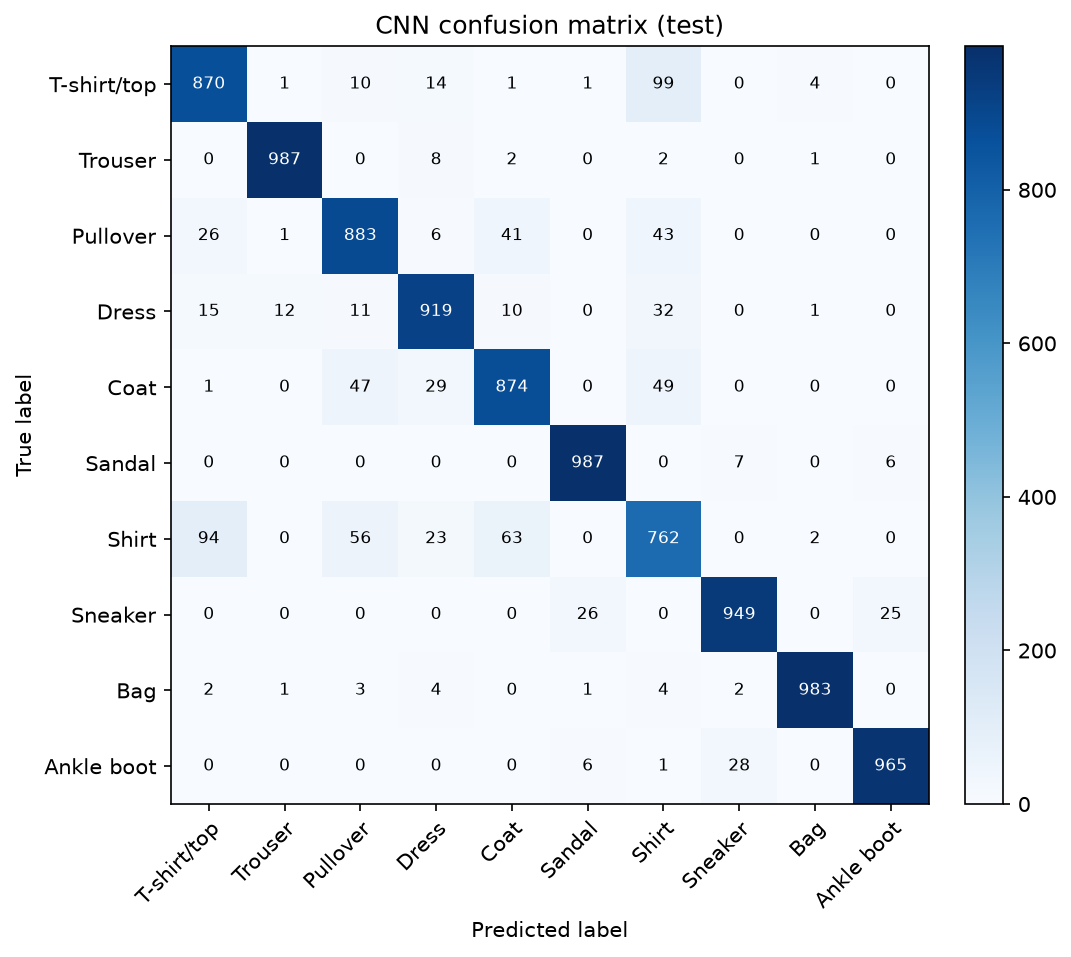

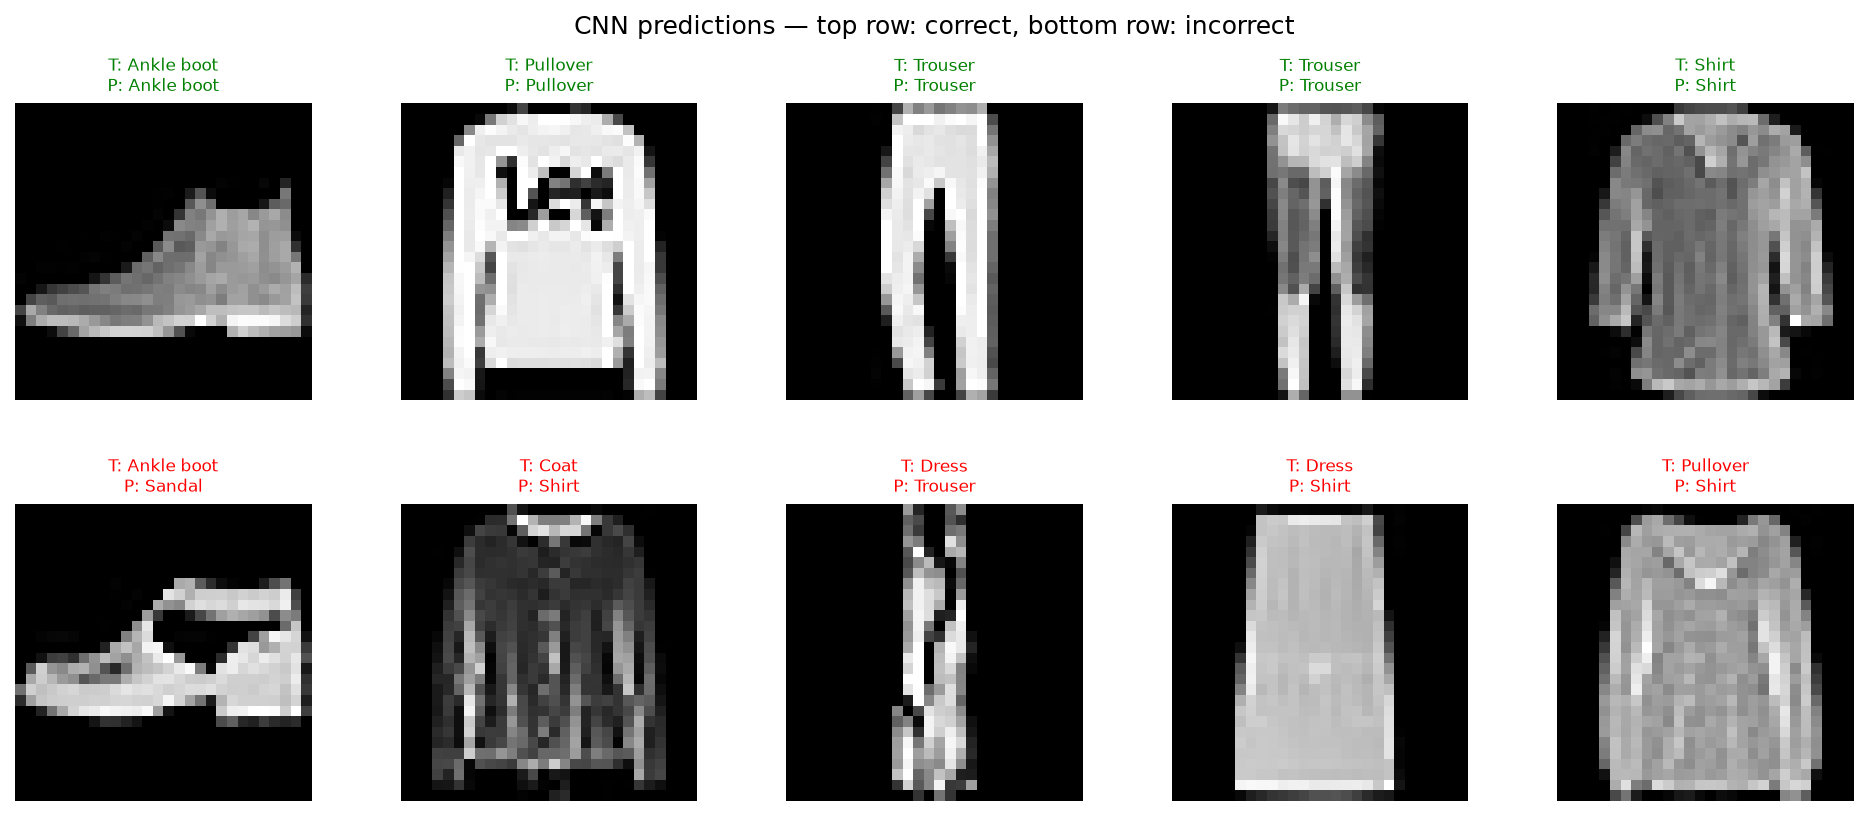

### GRU


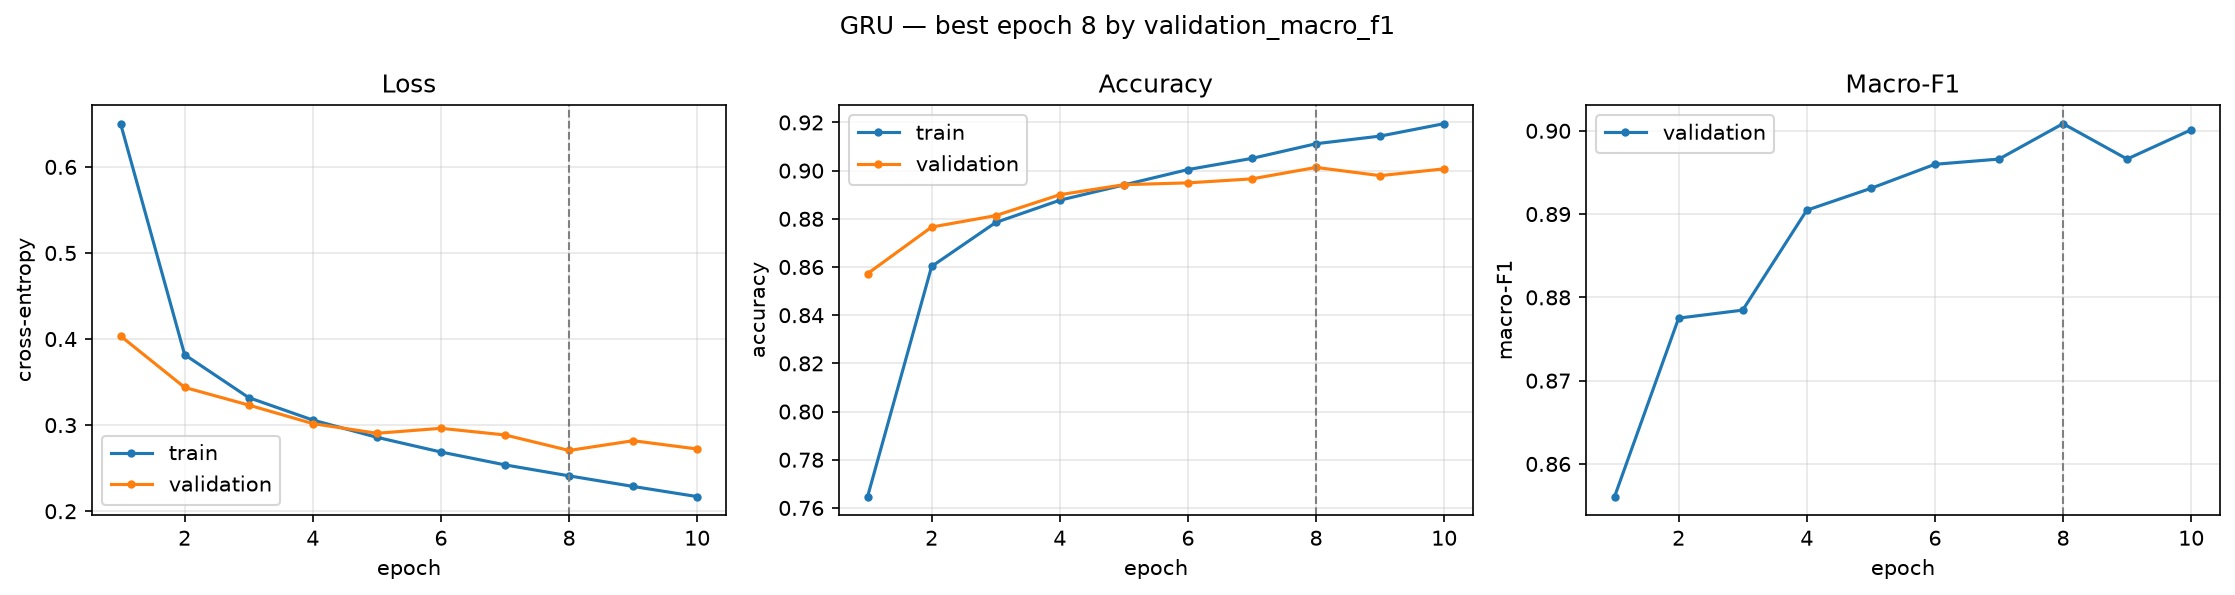

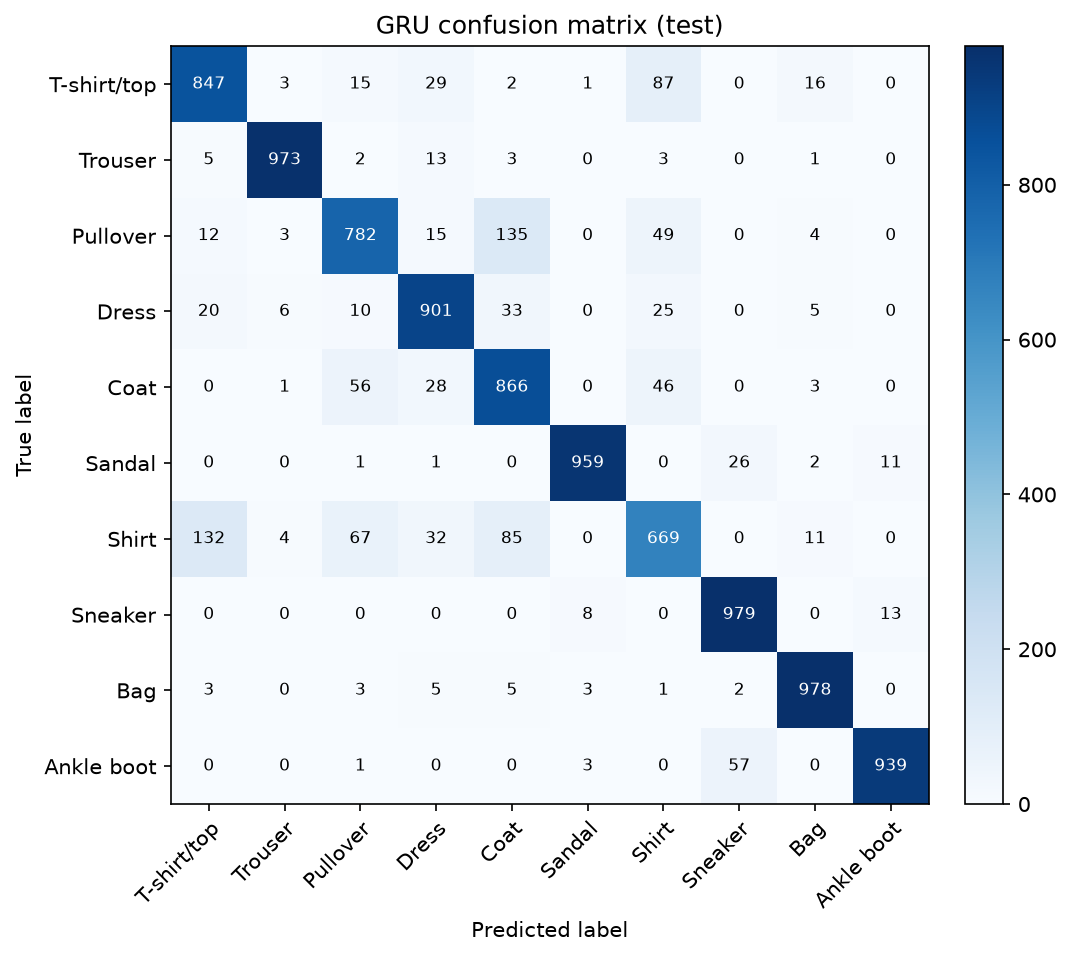

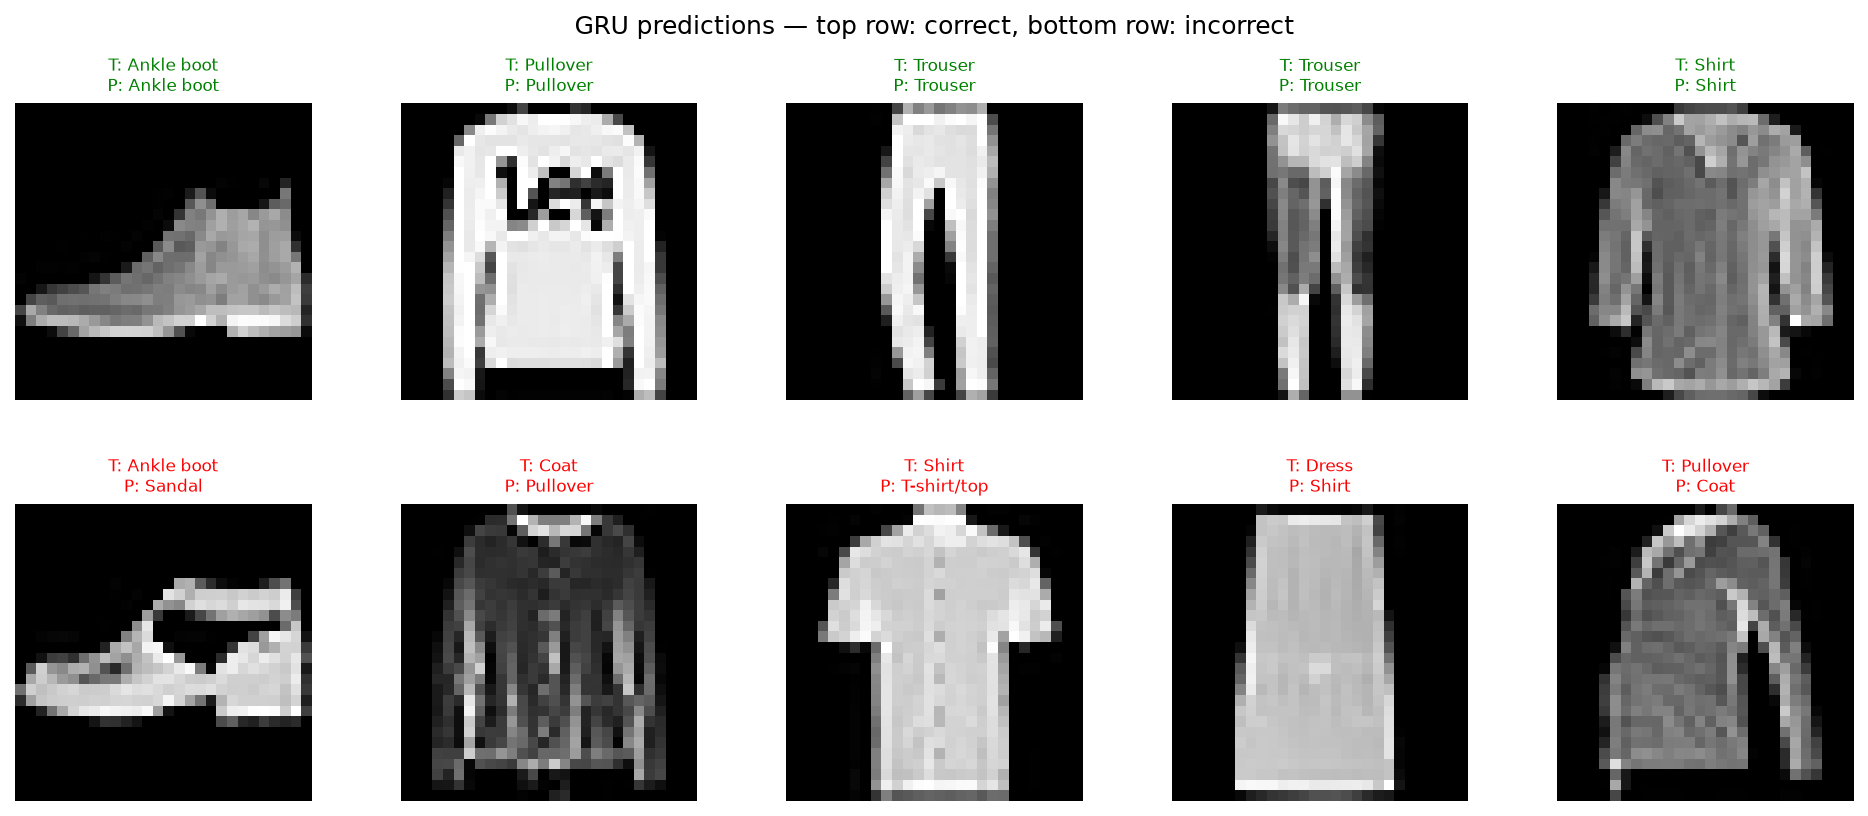

### Transformer


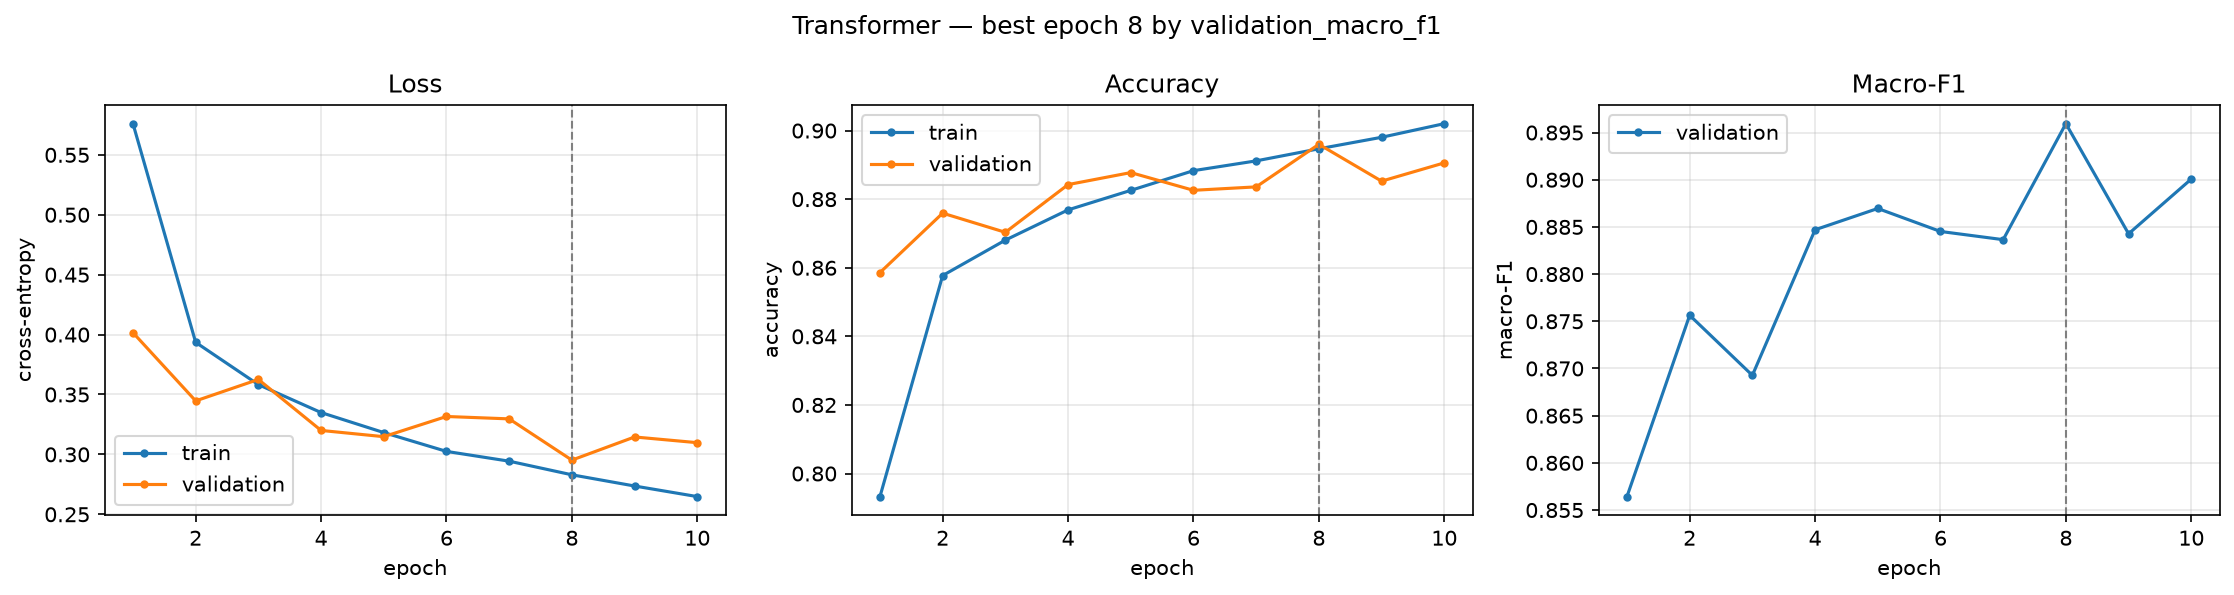

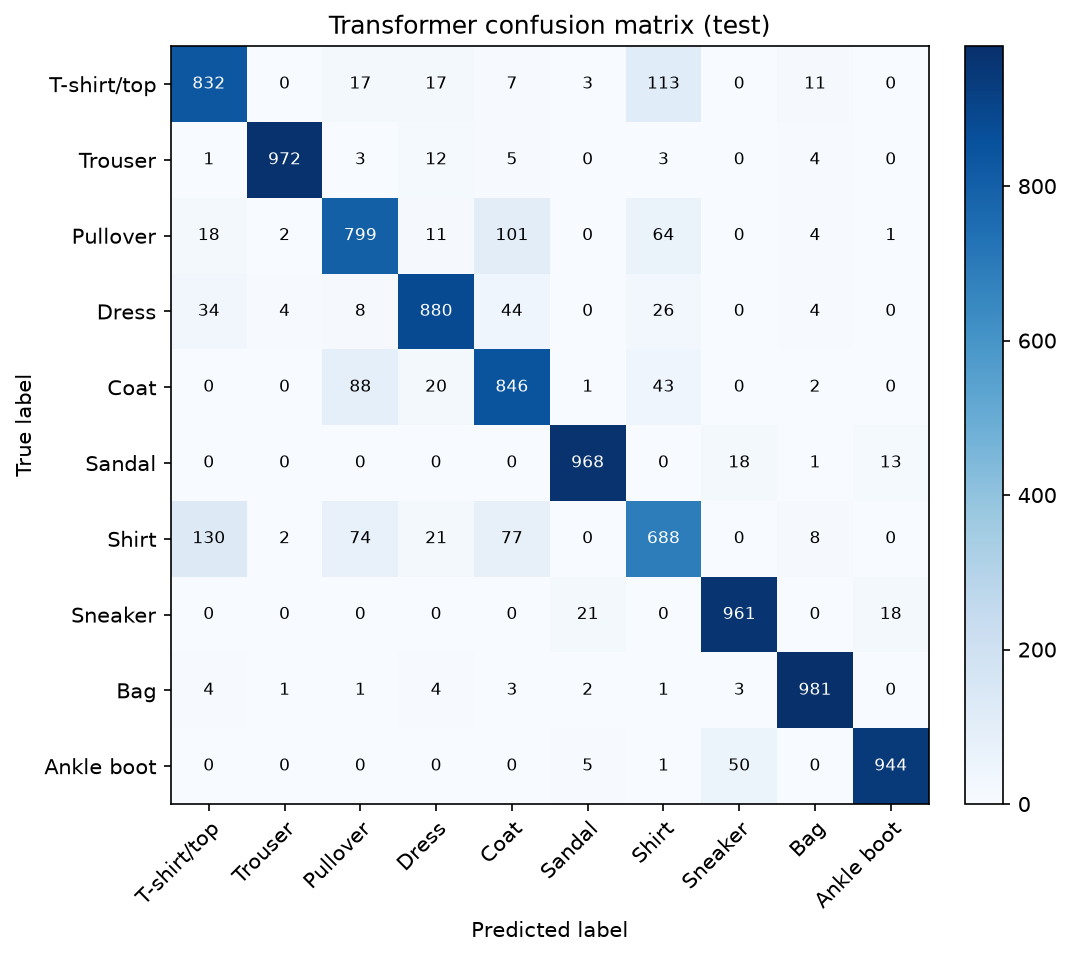

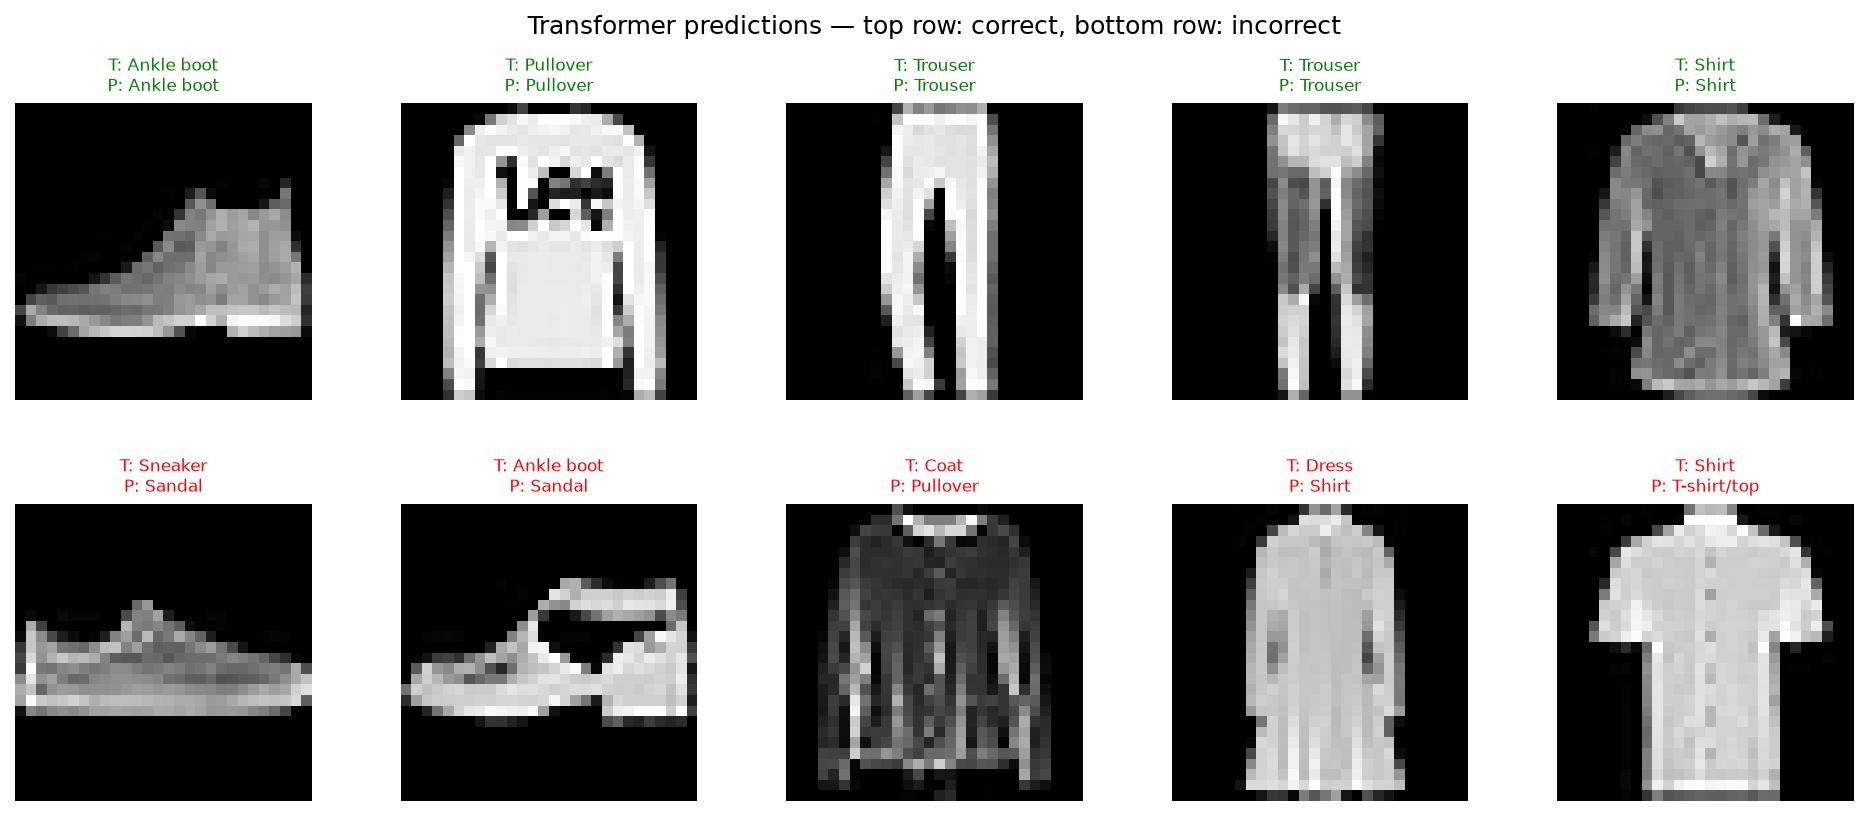

In [9]:
from IPython.display import Image, display

for display_name in model_builders:
    print(f"### {display_name}")
    display(Image(filename=str(RESULTS_DIR / "curves" / f"{display_name.lower()}.png")))
    display(Image(filename=str(RESULTS_DIR / "confusion" / f"{display_name.lower()}.png")))
    display(Image(filename=str(RESULTS_DIR / "examples" / f"{display_name.lower()}.png")))
